Stage 1 — Meet the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


orders=pd.read_csv('chennai-food-orders.csv')

print("Shape:", orders.shape)

print("\nData Types:")
print(orders.dtypes)

print("\nFirst 5 rows:")
print(orders.head())

Shape: (123, 10)

Data Types:
order_id                 str
order_date               str
area                     str
restaurant_type          str
distance_km          float64
prep_time_min        float64
delivery_time_min    float64
order_value            int64
rating               float64
payment_mode             str
dtype: object

First 5 rows:
  order_id  order_date        area restaurant_type  distance_km  \
0  ORD1042  2026-08-11         OMR       Fast Food          6.1   
1  ORD1103  2026-08-26  Anna Nagar    South Indian          3.6   
2  ORD1005  2026-08-02         omr         Biryani          4.2   
3  ORD1035  2026-08-09   Velachery    South Indian          7.1   
4  ORD1075  2026-08-19     T Nagar         Biryani          1.2   

   prep_time_min  delivery_time_min  order_value  rating payment_mode  
0            9.0               33.0          241     4.6         Card  
1           17.0               32.0          148     5.0         Card  
2           18.0               3

One row represents one food delivery order placed in Chennai during August 2026.

Conclusion: The dataset contains 123 food delivery orders and 10 columns, with information about the order date, Chennai delivery area, restaurant type, distance, preparation time, delivery time, order value, rating, and payment mode.

Stage 2 — Check the data's health

In [2]:
print("Duplicate rows:", orders.duplicated().sum())

# Remove duplicate rows because they represent repeated records.
clean = orders.drop_duplicates().copy()

print("Rows after removing duplicates:", clean.shape[0])

print("Missing values:")
print(clean.isna().sum())

print("\nMissing percentage:")
print(clean.isna().mean() * 100)

print("Areas:")
print(clean["area"].value_counts())

print("\nRestaurant types:")
print(clean["restaurant_type"].value_counts())

print("\nPayment modes:")
print(clean["payment_mode"].value_counts())

print("\nRatings:")
print(clean["rating"].value_counts().sort_index())

print("Order value statistics:")
print(clean["order_value"].describe())

print("\nLargest order values:")
print(clean["order_value"].sort_values(ascending=False).head(10))

print("Rows with impossible rating:")
print(clean[clean["rating"] > 5])
print(clean[clean["area"].isin(["omr", "O.M.R", "velachery"])])

print("Rows with missing values:")
print(clean[clean.isna().any(axis=1)])

# Standardized area names because different spellings/capitalization represented the same areas.
clean["area"] = clean["area"].replace({
    "omr": "OMR",
    "O.M.R": "OMR",
    "velachery": "Velachery"
})

print(clean["area"].value_counts())

# Rating 50 is impossible because valid ratings are between 1 and 5, so it is treated as missing.
clean.loc[clean["rating"] > 5, "rating"] = pd.NA

print(clean[clean["order_value"] == 12800])

# 12800 has an extra digit compared with similar orders, so correct it to 1280.
clean.loc[clean["order_value"] == 12800, "order_value"] = 1280

print(clean.loc[clean["order_id"] == "ORD1060", "order_value"])

print(clean["area"].unique())

# Remove accidental leading/trailing spaces from area names.
clean["area"] = clean["area"].str.strip()

# Standardize area names with inconsistent capitalization/spelling.
clean["area"] = clean["area"].replace({
    "omr": "OMR",
    "O.M.R": "OMR",
    "velachery": "Velachery"
})

print(clean["area"].value_counts())

print(clean.isna().sum())

Duplicate rows: 3
Rows after removing duplicates: 120
Missing values:
order_id              0
order_date            0
area                  0
restaurant_type       0
distance_km           1
prep_time_min         3
delivery_time_min     7
order_value           0
rating               18
payment_mode          0
dtype: int64

Missing percentage:
order_id              0.000000
order_date            0.000000
area                  0.000000
restaurant_type       0.000000
distance_km           0.833333
prep_time_min         2.500000
delivery_time_min     5.833333
order_value           0.000000
rating               15.000000
payment_mode          0.000000
dtype: float64
Areas:
area
Velachery     42
OMR           27
Adyar         19
T Nagar       15
Anna Nagar    12
omr            1
O.M.R          1
velachery      1
Velachery      1
OMR            1
Name: count, dtype: int64

Restaurant types:
restaurant_type
Fast Food       27
South Indian    25
Biryani         24
North Indian    17
Chinese     

Conclusion: After removing 3 duplicate rows and correcting inconsistent area names, the dataset contains 120 orders. The impossible 50.0 rating was treated as missing and the erroneous ₹12,800 order value was corrected to ₹1,280. Missing numerical values were retained as missing rather than artificially filling them.

Stage 3 — Describe each numeric column


 distance_km
Mean: 4.978151260504203
Median: 5.0
Mode: 3.6
Standard deviation: 1.9449700300015755
Skewness: 0.29501514962981706

 prep_time_min
Mean: 19.17094017094017
Median: 19.0
Mode: 19.0
Standard deviation: 5.293604792073685
Skewness: -0.01972128894483429

 delivery_time_min
Mean: 41.05309734513274
Median: 39.0
Mode: 41.0
Standard deviation: 24.859548577948228
Skewness: 6.379723595085863

 order_value
Mean: 262.65833333333336
Median: 244.0
Mode: 90
Standard deviation: 136.0383964479266
Skewness: 3.673900762941993

 rating
Mean: 4.788118811881188
Median: 5.0
Mode: 5.0
Standard deviation: 0.30505315232361435
Skewness: -1.3901507495815402
                         Mean  Median  Mode  Standard Deviation  Skewness
distance_km          4.978151     5.0   3.6            1.944970  0.295015
prep_time_min       19.170940    19.0  19.0            5.293605 -0.019721
delivery_time_min   41.053097    39.0  41.0           24.859549  6.379724
order_value        262.658333   244.0  90.0          1

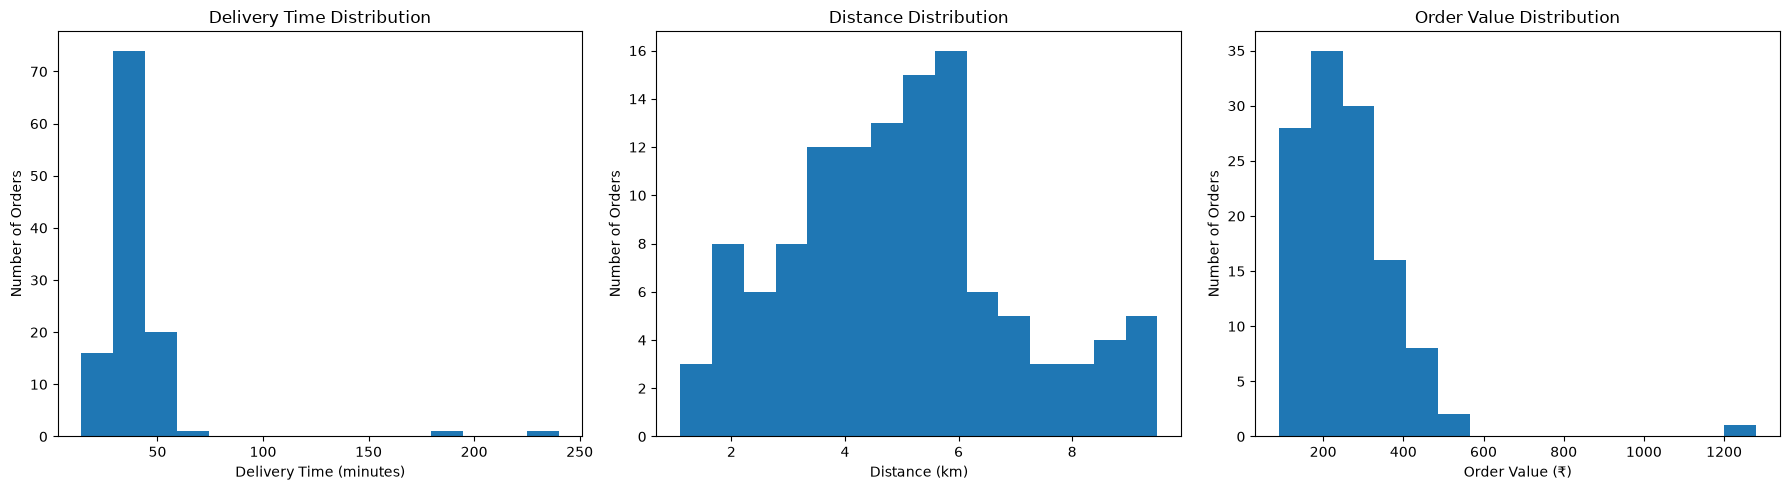

In [3]:
numeric_cols = [
    "distance_km",
    "prep_time_min",
    "delivery_time_min",
    "order_value",
    "rating"
]

for col in numeric_cols:
    print("\n", col)
    print("Mean:", clean[col].mean())
    print("Median:", clean[col].median())
    print("Mode:", clean[col].mode().iloc[0])
    print("Standard deviation:", clean[col].std())
    print("Skewness:", clean[col].skew())

    stats = pd.DataFrame(index=numeric_cols)

stats["Mean"] = clean[numeric_cols].mean()
stats["Median"] = clean[numeric_cols].median()
stats["Mode"] = clean[numeric_cols].mode().iloc[0]
stats["Standard Deviation"] = clean[numeric_cols].std()
stats["Skewness"] = clean[numeric_cols].skew()

print(stats)

# Create one window containing 3 histograms
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram 1: Delivery Time
axes[0].hist(clean["delivery_time_min"].dropna(), bins=15)
axes[0].set_title("Delivery Time Distribution")
axes[0].set_xlabel("Delivery Time (minutes)")
axes[0].set_ylabel("Number of Orders")

# Histogram 2: Distance
axes[1].hist(clean["distance_km"].dropna(), bins=15)
axes[1].set_title("Distance Distribution")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Number of Orders")

# Histogram 3: Order Value
axes[2].hist(clean["order_value"].dropna(), bins=15)
axes[2].set_title("Order Value Distribution")
axes[2].set_xlabel("Order Value (₹)")
axes[2].set_ylabel("Number of Orders")

plt.tight_layout()
plt.show()

The median is a better measure of typical delivery time because delivery time is strongly right-skewed by a few unusually long deliveries.

Delivery time and order value are strongly right-skewed, indicating a small number of unusually high values, while distance and preparation time are relatively balanced. The median is more representative than the mean for delivery time and order value.

Stage 4: Detect and handle outliers

In [4]:
# Calculate IQR for delivery time
Q1 = clean["delivery_time_min"].quantile(0.25)
Q3 = clean["delivery_time_min"].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

delivery_outliers = clean[
    (clean["delivery_time_min"] < lower_fence) |
    (clean["delivery_time_min"] > upper_fence)
]

print("Number of delivery time outliers:", len(delivery_outliers))
print("\nDelivery time outliers:")
print(delivery_outliers)

# Inspect the outlier orders with their key details
print(clean.loc[
    clean["order_id"].isin(["ORD1101", "ORD1083", "ORD1049", "ORD1026"]),
    ["order_id", "order_date", "area", "restaurant_type",
     "distance_km", "prep_time_min", "delivery_time_min",
     "order_value", "rating"]
].to_string(index=False))


Q1: 32.0
Q3: 43.0
IQR: 11.0
Lower fence: 15.5
Upper fence: 59.5
Number of delivery time outliers: 4

Delivery time outliers:
    order_id  order_date        area restaurant_type  distance_km  \
32   ORD1101  2026-08-26         OMR         Biryani          9.5   
50   ORD1083  2026-08-21         OMR       Fast Food          4.5   
80   ORD1049  2026-08-13  Anna Nagar       Fast Food          1.8   
102  ORD1026  2026-08-07   Velachery        Desserts          2.2   

     prep_time_min  delivery_time_min  order_value  rating payment_mode  
32            32.0               62.0          325     NaN         Card  
50            16.0              240.0          178     5.0          UPI  
80             6.0               14.0          229     NaN         Card  
102           23.0              185.0           90     5.0         Cash  
order_id order_date       area restaurant_type  distance_km  prep_time_min  delivery_time_min  order_value  rating
 ORD1101 2026-08-26        OMR         Birya

### Outlier Decisions

IQR identified four unusual delivery times. Outliers were reviewed individually rather than removed automatically. ORD1101 is a genuine long-distance extreme, ORD1083 is a genuine weather-related extreme, and ORD1049 is a genuine unusually fast delivery. ORD1026 requires further investigation because the available data does not provide enough information to determine whether it is an error or a genuine extreme.

In [5]:
Q1_value = clean["order_value"].quantile(0.25)
Q3_value = clean["order_value"].quantile(0.75)

IQR_value = Q3_value - Q1_value

lower_fence_value = Q1_value - 1.5 * IQR_value
upper_fence_value = Q3_value + 1.5 * IQR_value

print("Q1:", Q1_value)
print("Q3:", Q3_value)
print("IQR:", IQR_value)
print("Lower fence:", lower_fence_value)
print("Upper fence:", upper_fence_value)

value_outliers = clean[
    (clean["order_value"] < lower_fence_value) |
    (clean["order_value"] > upper_fence_value)
]

print("\nNumber of order value outliers:", len(value_outliers))
print("\nOrder value outliers:")
print(value_outliers[
    ["order_id", "order_date", "area", "restaurant_type",
     "distance_km", "prep_time_min", "delivery_time_min",
     "order_value", "rating"]
].to_string(index=False))

Q1: 177.25
Q3: 319.5
IQR: 142.25
Lower fence: -36.125
Upper fence: 532.875

Number of order value outliers: 1

Order value outliers:
order_id order_date      area restaurant_type  distance_km  prep_time_min  delivery_time_min  order_value  rating
 ORD1060 2026-08-16 Velachery    South Indian          2.1           22.0               36.0         1280     5.0


### Order Value Outlier Decision

The IQR method identified one order-value outlier, ORD1060, with an order value of ₹1,280. The original value was ₹12,800, which appeared to contain an extra digit and was corrected to ₹1,280 during cleaning. Although ₹1,280 remains statistically high, it is a plausible genuine high-value order, so it was retained rather than removed.

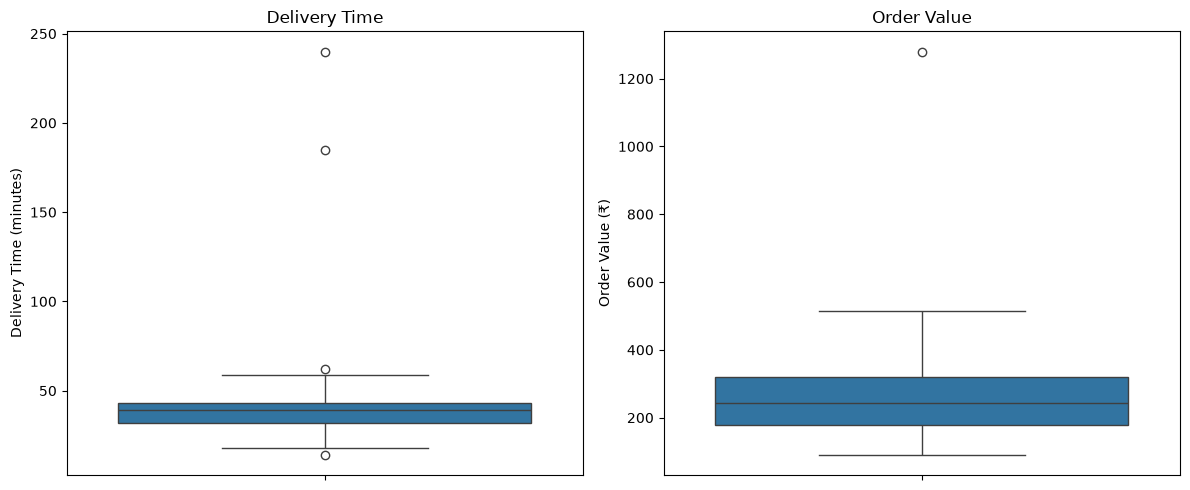

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=clean["delivery_time_min"], ax=axes[0])
axes[0].set_title("Delivery Time")
axes[0].set_ylabel("Delivery Time (minutes)")

sns.boxplot(y=clean["order_value"], ax=axes[1])
axes[1].set_title("Order Value")
axes[1].set_ylabel("Order Value (₹)")

plt.tight_layout()
plt.show()

**Conclusion:** The box plots show that delivery time and order value contain unusual observations, including a few very high delivery times and one unusually high order value.

Stage 5.1 — Correlation Matrix

                   distance_km  prep_time_min  delivery_time_min  order_value  \
distance_km           1.000000       0.158486           0.150843     0.125218   
prep_time_min         0.158486       1.000000           0.223581     0.238461   
delivery_time_min     0.150843       0.223581           1.000000    -0.030755   
order_value           0.125218       0.238461          -0.030755     1.000000   
rating               -0.045358      -0.180974           0.052624     0.062042   

                     rating  
distance_km       -0.045358  
prep_time_min     -0.180974  
delivery_time_min  0.052624  
order_value        0.062042  
rating             1.000000  


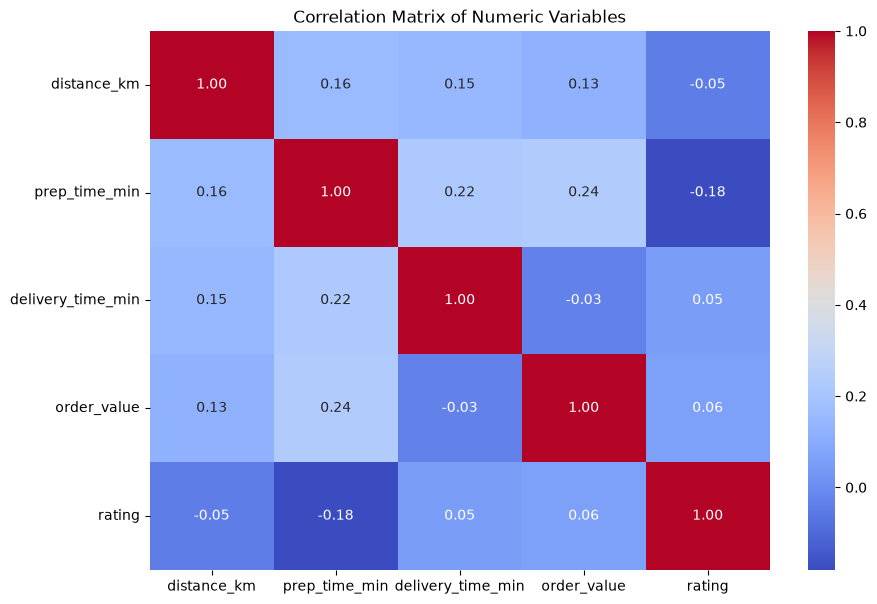

In [7]:
correlation = clean.select_dtypes(include="number").corr()

print(correlation)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numeric Variables")
plt.show()

**Conclusion:** Preparation time has the strongest positive correlation with delivery time (0.22), while distance has a weaker positive correlation (0.15); the relationships are weak overall.

Stage 5.2 — Before vs After Cleaning

In [9]:
# Correlation before cleaning
correlation_before = orders.select_dtypes(include="number").corr()

# Correlation after cleaning
correlation_after = clean.select_dtypes(include="number").corr()

print("Correlation with delivery time BEFORE cleaning:")
print(correlation_before["delivery_time_min"].sort_values(ascending=False))

print("\nCorrelation with delivery time AFTER cleaning:")
print(correlation_after["delivery_time_min"].sort_values(ascending=False))

Correlation with delivery time BEFORE cleaning:
delivery_time_min    1.000000
prep_time_min        0.234167
distance_km          0.160495
rating               0.002049
order_value         -0.019239
Name: delivery_time_min, dtype: float64

Correlation with delivery time AFTER cleaning:
delivery_time_min    1.000000
prep_time_min        0.223581
distance_km          0.150843
rating               0.052624
order_value         -0.030755
Name: delivery_time_min, dtype: float64


**Conclusion:** Cleaning slightly changed the correlations with delivery time, but the overall pattern remained similar, with preparation time showing the strongest positive relationship.

Stage 5.3 — Scatter Plots

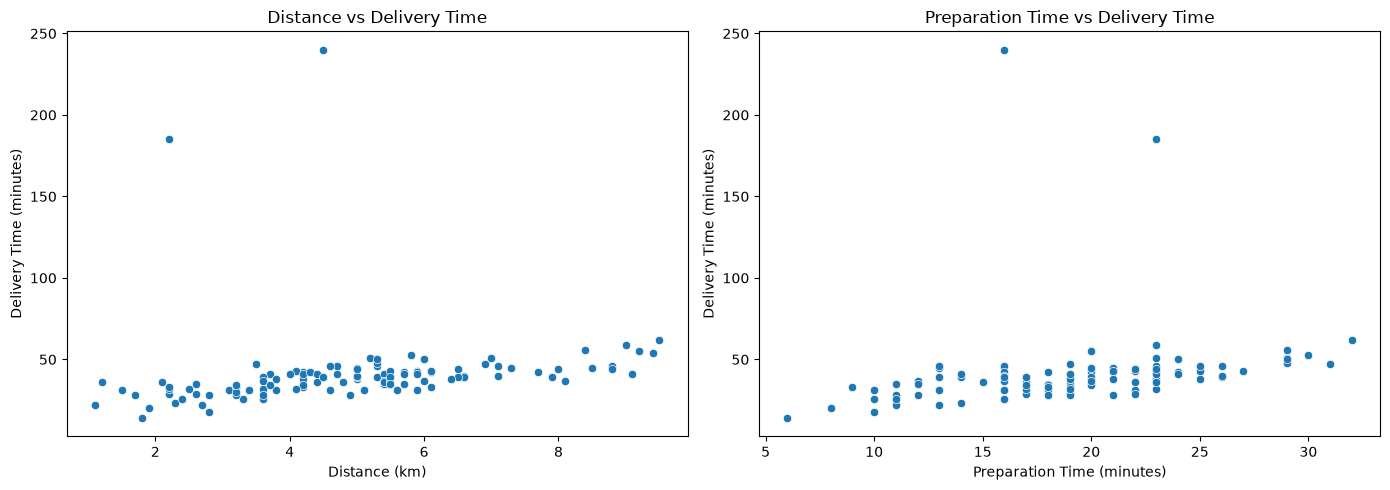

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=clean,
    x="distance_km",
    y="delivery_time_min",
    ax=axes[0]
)

axes[0].set_title("Distance vs Delivery Time")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Delivery Time (minutes)")


sns.scatterplot(
    data=clean,
    x="prep_time_min",
    y="delivery_time_min",
    ax=axes[1]
)

axes[1].set_title("Preparation Time vs Delivery Time")
axes[1].set_xlabel("Preparation Time (minutes)")
axes[1].set_ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

**Conclusion:** Both distance and preparation time show a weak positive relationship with delivery time, with preparation time showing the slightly stronger relationship.

Stage 5.4 — Which area has the slowest average delivery?

In [11]:
area_delivery = clean.groupby("area")["delivery_time_min"].mean().sort_values(ascending=False)

print(area_delivery)

area
OMR           44.900000
Velachery     43.073171
T Nagar       37.923077
Anna Nagar    37.000000
Adyar         34.894737
Name: delivery_time_min, dtype: float64


**Conclusion:** OMR has the highest average delivery time at 44.90 minutes, followed by Velachery at 43.07 minutes.

Stage 5.5 — Which restaurant type has the longest preparation time?

In [12]:
restaurant_prep = (
    clean.groupby("restaurant_type")["prep_time_min"]
    .mean()
    .sort_values(ascending=False)
)

print(restaurant_prep)

restaurant_type
Biryani         23.416667
Desserts        20.800000
Chinese         18.470588
South Indian    18.375000
Fast Food       17.346154
North Indian    16.687500
Name: prep_time_min, dtype: float64


**Conclusion:** Biryani has the longest average preparation time at 23.42 minutes, while North Indian has the shortest at 16.69 minutes.

Stage 5.6 — Probability of delivery taking more than 45 minutes

In [13]:
delivery_data = clean["delivery_time_min"].dropna()

slow_orders = (delivery_data > 45).sum()
total_orders = delivery_data.count()

probability = slow_orders / total_orders
percentage = probability * 100

print("Orders with delivery time > 45 minutes:", slow_orders)
print("Orders with recorded delivery time:", total_orders)
print("Probability:", probability)
print("Percentage:", percentage, "%")

Orders with delivery time > 45 minutes: 20
Orders with recorded delivery time: 113
Probability: 0.17699115044247787
Percentage: 17.699115044247787 %


**Conclusion:** 20 out of 113 orders with recorded delivery times took more than 45 minutes, giving a probability of 17.70%.

Stage 6 — Final Business Summary

Finding 1 — Delivery-time relationships

Preparation time has the strongest positive correlation with delivery time (0.22), followed by distance (0.15), although both relationships are weak.

Finding 2 — Area performance

OMR has the highest average delivery time at 44.90 minutes, followed by Velachery at 43.07 minutes.

Finding 3 — Slow-order frequency

20 of 113 orders with recorded delivery times took more than 45 minutes, representing 17.70% of observed orders.

Recommendation 1:

Investigate OMR deliveries separately to identify operational reasons for its higher average delivery time, such as restaurant preparation, route distance, or traffic-related factors.

Recommendation 2:

Focus on reducing kitchen preparation time, particularly for Biryani orders, because Biryani had the highest average preparation time at 23.42 minutes and preparation time had the strongest correlation with delivery time.



Limitation

The dataset contains only 123 orders from August, with 7 missing delivery-time values, so the findings may not represent all orders or other time periods.